In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/greatnigga/metalforming-project-turning-operation-dataset/metalforming project turning operation dataset.xlsx


  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
category-encoders 2.11.1 requires scikit-learn>=1.6.0, but you have scikit-learn 1.5.0 which is incompatible.
tpot 1.1.0 requires scikit-learn>=1.6, but you have scikit-learn 1.5.0 which is incompatible.
umap-learn 0.5.12 requires scikit-learn>=1.6, but you have scikit-learn 1.5.0 which is incompatible.
hdbscan 0.8.44 requires scikit-learn>=1.6, but you have scikit-learn 1.5.0 which is incompatible.
Running Scikit-Learn Version: 1.5.0 (Must be 1.5.0)
Successfully located file at: /kaggle/input/datasets/greatnigga/metalforming-project-turning-operation-dataset/metalforming project turning operation dataset.xlsx

Training the machine learnin

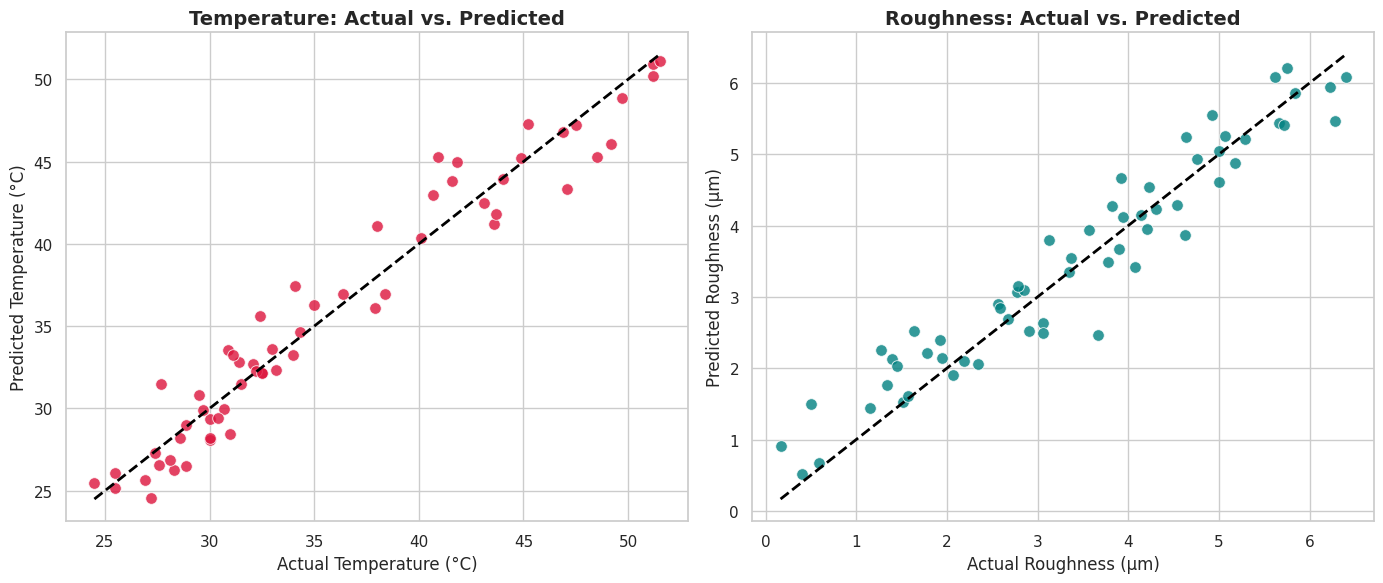


Model saved successfully as 'lathe_predictive_model.joblib'


In [2]:
# 1. FORCE THE KAGGLE ENVIRONMENT TO USE VERSION 1.5.0
!pip install scikit-learn==1.5.0 -q

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, r2_score
import joblib

# Verify the correct version loaded
print(f"Running Scikit-Learn Version: {sklearn.__version__} (Must be 1.5.0)")

# 2. AUTO-LOCATE THE DATASET
file_path = None
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        if filename.endswith('.xlsx') or filename.endswith('.xls'):
            file_path = os.path.join(dirname, filename)
            break

if file_path is None:
    raise FileNotFoundError("Could not find any Excel file in the Kaggle input directory. Please ensure the dataset is attached.")
print(f"Successfully located file at: {file_path}")

# Read the Excel file into a Pandas DataFrame
df = pd.read_excel(file_path)

# 3. PREPARE FEATURES (X) AND TARGETS (Y)
X = df[['Material', 'RPM', 'Feed', 'Depth']]
y = df[['Temp', 'Roughness']]

# 4. TRAIN/TEST SPLIT
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 5. BUILD THE PIPELINE
preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore'), ['Material'])
    ],
    remainder='passthrough'
)

model_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', RandomForestRegressor(n_estimators=300, max_depth=12, random_state=42))
])

# 6. TRAIN THE MODEL
print("\nTraining the machine learning model...")
model_pipeline.fit(X_train, y_train)

# 7. EVALUATE THE RESULTS
y_pred = model_pipeline.predict(X_test)

r2_temp = r2_score(y_test.iloc[:, 0], y_pred[:, 0])
mae_temp = mean_absolute_error(y_test.iloc[:, 0], y_pred[:, 0])

r2_rough = r2_score(y_test.iloc[:, 1], y_pred[:, 1])
mae_rough = mean_absolute_error(y_test.iloc[:, 1], y_pred[:, 1])

print("\n--- MODEL PERFORMANCE METRICS ---")
print(f"Temperature Prediction -> R-Squared: {r2_temp:.4f} | MAE: {mae_temp:.2f} °C")
print(f"Roughness Prediction   -> R-Squared: {r2_rough:.4f} | MAE: {mae_rough:.3f} µm")

# 8. VISUALIZE THE RESULTS GRAPHICALLY
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

sns.scatterplot(x=y_test.iloc[:, 0], y=y_pred[:, 0], ax=axes[0], color='crimson', s=70, alpha=0.8)
axes[0].plot([y_test.iloc[:, 0].min(), y_test.iloc[:, 0].max()], 
             [y_test.iloc[:, 0].min(), y_test.iloc[:, 0].max()], 
             color='black', linestyle='--', linewidth=2)
axes[0].set_title('Temperature: Actual vs. Predicted', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Actual Temperature (°C)', fontsize=12)
axes[0].set_ylabel('Predicted Temperature (°C)', fontsize=12)

sns.scatterplot(x=y_test.iloc[:, 1], y=y_pred[:, 1], ax=axes[1], color='teal', s=70, alpha=0.8)
axes[1].plot([y_test.iloc[:, 1].min(), y_test.iloc[:, 1].max()], 
             [y_test.iloc[:, 1].min(), y_test.iloc[:, 1].max()], 
             color='black', linestyle='--', linewidth=2)
axes[1].set_title('Roughness: Actual vs. Predicted', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Actual Roughness (µm)', fontsize=12)
axes[1].set_ylabel('Predicted Roughness (µm)', fontsize=12)

plt.tight_layout()
plt.savefig('Prediction_Accuracy_Graphs.png', dpi=300)
plt.show()

# 9. EXPORT FOR STREAMLIT
export_filename = 'lathe_predictive_model.joblib'
joblib.dump(model_pipeline, export_filename)
print(f"\nModel saved successfully as '{export_filename}'")

In [3]:
import sklearn
print(sklearn.__version__)

1.5.0
